# Class-weighted chord-refinement Transformer: controlled experiment

This notebook creates a **separate weighted experiment**. Notebooks 05/06, the baseline checkpoint, architecture, saved vocabularies, preprocessing and split assignments are read-only.

The experimental change is training cross-entropy with training-only class weights. Model configuration, seed, batch size, optimizer, clipping, scheduler and early stopping match the recorded baseline. Primary checkpoint selection remains **unweighted validation cross-entropy**. Evaluation compares both saved checkpoints with one implementation; baseline training is not repeated.

Run all cells with the repository `.venv` kernel. CPU/Windows is supported. Every execution creates a new protected directory under `outputs/weighted_transformer/`.

## 1. Imports and existing architecture

In [1]:
from pathlib import Path
import sys
root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p/'experiments/rahul/src').is_dir()), None)
if root is None:
    raise RuntimeError('Run this notebook from within the vocal-harmonization repository')
if str(root) not in sys.path:
    sys.path.insert(0,str(root))
import bisect
from dataclasses import asdict
from datetime import datetime, timedelta, timezone
import hashlib
import json
import random
import time
import numpy as np
import torch
from torch.utils.data import Dataset
import matplotlib.pyplot as plt
from IPython.display import display
from experiments.rahul.src.model import DatasetSpec, ModelConfig, ChordRefinementTransformer, masked_cross_entropy
from experiments.rahul.src.model.checkpoint import save_checkpoint, load_checkpoint
from experiments.rahul.src.transformer_dataset import SavedSequenceDataset, make_dataloader, collate_sequences
print('PyTorch:',torch.__version__,'CUDA available:',torch.cuda.is_available())

Matplotlib is building the font cache; this may take a moment.


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\srjay\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


PyTorch: 2.14.1+cpu CUDA available: False


In [2]:
import ast, csv
import nbformat
from torch.nn import functional as F
from experiments.rahul.src.create_sequences import validate_splits
from experiments.rahul.src.weighted_training import (
    supervised_mask, count_training_targets, sqrt_inverse_weights,
    weighted_masked_cross_entropy, metrics_from_confusion, quality_metrics,
)

## 2. Baseline configuration and exact inputs

Settings are loaded from the completed baseline's recorded configuration. The corresponding literal settings are also read from notebook 06 and checked for agreement. No settings are silently changed. The same 17 musical inputs and two target fields are used.

In [3]:
INPUT_KEYS = (
    'basic_chord_ids', 'melody_pitch_ids', 'melody_timing', 'melody_note_mask',
    'melody_silent', 'key_ids', 'mode_ids', 'roman_ids', 'harmonic_function_ids',
    'genre_features', 'beat_index', 'bar_number', 'beat_position', 'event_duration',
    'relative_bar_number', 'beat_timing_known_mask', 'beat_attention_mask',
)
TARGET_KEYS = ('target_chord_ids','target_loss_mask')
assert len(INPUT_KEYS)==17
print('Inputs:'); print('\n'.join('inputs__'+k for k in INPUT_KEYS))
print('Targets:'); print('\n'.join('targets__'+k for k in TARGET_KEYS))

Inputs:
inputs__basic_chord_ids
inputs__melody_pitch_ids
inputs__melody_timing
inputs__melody_note_mask
inputs__melody_silent
inputs__key_ids
inputs__mode_ids
inputs__roman_ids
inputs__harmonic_function_ids
inputs__genre_features
inputs__beat_index
inputs__bar_number
inputs__beat_position
inputs__event_duration
inputs__relative_bar_number
inputs__beat_timing_known_mask
inputs__beat_attention_mask
Targets:
targets__target_chord_ids
targets__target_loss_mask


In [4]:
BASELINE_RUN = root/'experiments/rahul/outputs/transformer_training/notebook_full_inputs_20261019_194104_127905'
BASELINE_NOTEBOOK = root/'experiments/rahul/notebooks/06_train_transformer.ipynb'
ARCHITECTURE_NOTEBOOK = root/'experiments/rahul/notebooks/05_transformer_architecture.ipynb'
baseline_config=json.loads((BASELINE_RUN/'training_config.json').read_text())
baseline_nb=nbformat.read(BASELINE_NOTEBOOK,as_version=4)
setting_names={'SEED':'seed','MAX_EPOCHS':'max_epochs','BATCH_SIZE':'batch_size',
               'LEARNING_RATE':'learning_rate','PATIENCE':'patience','THREADS':'threads'}
notebook_literals={}
for cell in baseline_nb.cells:
    if cell.cell_type!='code': continue
    for statement in ast.parse(cell.source).body:
        if isinstance(statement,ast.Assign):
            for target in statement.targets:
                if isinstance(target,ast.Name) and target.id in setting_names:
                    notebook_literals[target.id]=ast.literal_eval(statement.value)
for name,key in setting_names.items():
    assert notebook_literals[name]==baseline_config[key],f'Baseline settings differ: {name}'
SEED=baseline_config['seed']; MAX_EPOCHS=baseline_config['max_epochs']
BATCH_SIZE=baseline_config['batch_size']; LEARNING_RATE=baseline_config['learning_rate']
PATIENCE=baseline_config['patience']; THREADS=baseline_config['threads']
DEVICE=torch.device(baseline_config['device'])
DATASET_DIR=Path(baseline_config['dataset'])
if not DATASET_DIR.is_dir(): DATASET_DIR=root/'experiments/rahul/outputs/model_preprocessing/final_all_tracks_quality_v6_multibar'
assert ['inputs__'+k for k in INPUT_KEYS]==baseline_config['input_columns']
assert ['targets__'+k for k in TARGET_KEYS]==baseline_config['target_columns']
assert baseline_config['optimizer']=='AdamW'
assert baseline_config['scheduler']=='ReduceLROnPlateau(factor=0.5,patience=1)'
ALPHA=0.5; MAX_WEIGHT=5.0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(THREADS)
if DEVICE.type=='cuda':
    if not torch.cuda.is_available(): raise RuntimeError('Baseline CUDA device unavailable')
    torch.cuda.manual_seed_all(SEED)
run_stamp=datetime.now(timezone(timedelta(hours=5,minutes=30))).strftime('%Y%m%d_%H%M%S_%f')
RUN_DIR=root/'experiments/rahul/outputs/weighted_transformer'/('weighted_'+run_stamp)
print('Output:',RUN_DIR)
display({k:baseline_config[k] for k in ('seed','max_epochs','batch_size','learning_rate','patience','device','threads')})

Output: C:\Users\srjay\OneDrive\Desktop\Research\vocal-harmonization\experiments\rahul\outputs\weighted_transformer\weighted_20261020_003318_832489


{'seed': 42,
 'max_epochs': 10,
 'batch_size': 32,
 'learning_rate': 0.001,
 'patience': 3,
 'device': 'cpu',
 'threads': 4}

## 3. Original dataset helpers, split checks and protected inputs

The selected-shard caching helper is reused verbatim from notebook 06. All split/group leakage checks use the existing split manifest. A separate nonshuffled training loader counts labels without consuming the shuffled training loader's RNG. Neither validation nor test contributes to class frequencies.

In [5]:
def select_batch(batch, device):
    return ({key:batch['inputs'][key].to(device) for key in INPUT_KEYS},
            {key:batch['targets'][key].to(device) for key in TARGET_KEYS})

class CachedSelectedDataset(Dataset):
    def __init__(self, index_path):
        original = SavedSequenceDataset(index_path)
        if original._shards is None:
            self.shards, self.ends = [original], [len(original)]
        else:
            self.shards = [SavedSequenceDataset(p) for p in original._shards]
            self.ends = list(original._ends)
        keep = {'inputs__'+k for k in INPUT_KEYS} | {'targets__'+k for k in TARGET_KEYS}
        for shard in self.shards:
            shard.arrays = {k:v for k,v in shard.arrays.items()
                            if not k.startswith(('inputs__','targets__')) or k in keep}
    def __len__(self):
        return self.ends[-1]
    def __getitem__(self,index):
        if index<0: index+=len(self)
        if not 0<=index<len(self): raise IndexError(index)
        shard = bisect.bisect_right(self.ends,index)
        local = index-(self.ends[shard-1] if shard else 0)
        item = self.shards[shard][local]
        item['metadata']['sequence_index']=index
        return item

def atomic_json(path, value):
    path=Path(path)
    temporary=path.with_suffix(path.suffix+'.tmp')
    temporary.write_text(json.dumps(value,indent=2,allow_nan=False)+'\n',encoding='utf-8')
    temporary.replace(path)

def sha256_file(path):
    digest=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda:stream.read(8*1024*1024),b''): digest.update(chunk)
    return digest.hexdigest()

In [6]:
def write_csv(path, rows):
    if not rows: raise ValueError('Cannot export an empty report')
    fields=list(rows[0])
    with Path(path).open('w',newline='',encoding='utf-8') as stream:
        writer=csv.DictWriter(stream,fieldnames=fields)
        writer.writeheader(); writer.writerows(rows)
    with Path(path).open(newline='',encoding='utf-8') as stream:
        reread=list(csv.DictReader(stream))
    assert len(reread)==len(rows) and list(reread[0])==fields
    for original,saved in zip(rows,reread):
        for key,value in original.items():
            if value is None: assert saved[key]==''
            elif isinstance(value,(float,int)) and not isinstance(value,bool):
                assert float(saved[key])==float(value)
            else: assert saved[key]==str(value)

indices={split:json.loads((DATASET_DIR/f'{split}_sequences.json').read_text()) for split in ('train','validation','test')}
manifest=json.loads((DATASET_DIR/'split_manifest.json').read_text())
all_tracks=[t for group in manifest['splits'].values() for t in group]
validate_splits(manifest,all_tracks)
for split,index in indices.items():
    shard_tracks={str(int(Path(s['path']).stem.removeprefix('track_'))) for s in index['shards']}
    assert shard_tracks==set(manifest['splits'][split])
train_data=CachedSelectedDataset(DATASET_DIR/'train_sequences.json')
validation_data=CachedSelectedDataset(DATASET_DIR/'validation_sequences.json')
train_loader=make_dataloader(train_data,batch_size=BATCH_SIZE,shuffle=True,seed=SEED)
frequency_loader=make_dataloader(train_data,batch_size=BATCH_SIZE,shuffle=False,seed=SEED)
validation_loader=make_dataloader(validation_data,batch_size=BATCH_SIZE,shuffle=False,seed=SEED)
spec=DatasetSpec.from_folder(DATASET_DIR)
reserved_ids=tuple(i for i,label in enumerate(spec.target_labels) if label in ('PAD','UNK'))
protected_paths=[BASELINE_NOTEBOOK,ARCHITECTURE_NOTEBOOK,BASELINE_RUN/'best.pt',
                 BASELINE_RUN/'training_config.json',DATASET_DIR/'feature_vocabularies.json',
                 DATASET_DIR/'target_vocabulary.json',DATASET_DIR/'split_manifest.json']
protected_paths += [DATASET_DIR/f'{split}_sequences.json' for split in indices]
protected_paths += sorted((root/'experiments/rahul/src/model').glob('*.py'))
protected_paths += [root/'experiments/rahul/src/transformer_dataset.py',root/'experiments/rahul/src/encode_features.py']
protected_hashes={str(path):sha256_file(path) for path in protected_paths}
RUN_DIR.mkdir(parents=True,exist_ok=False)
atomic_json(RUN_DIR/'status.json',{'status':'counting_training_targets'})
display({split:{'sequences':idx['sequences'],'real_beats':idx['real_beats']} for split,idx in indices.items()})

{'train': {'sequences': 12718, 'real_beats': 186572},
 'validation': {'sequences': 814, 'real_beats': 11319},
 'test': {'sequences': 990, 'real_beats': 14278}}

## 4. Training-only imbalance and class weights

For each observed supervised **complete chord class** (root + quality + inversion),

$$w_c=\min\left(5,\left(\frac{N}{K n_c}\right)^{0.5}\right).$$

N is the valid training-target count, K the number of observed supervised training classes. PAD/UNK and any zero-frequency class receive zero weight; a supervised N class remains eligible. There is no extra normalization or quality-family collapsing. Weights cover the complete saved vocabulary. All counts apply target-loss and real-beat masks.

Valid training targets: 184867 Observed supervised classes: 400
Zero-training classes, including reserved: 2
Zero-training supervised classes: 0
20 most frequent:


[{'target_id': 2,
  'target_chord': 'N',
  'reserved': False,
  'training_count': 14904,
  'class_weight': 0.17609551548957825},
 {'target_id': 260,
  'target_chord': 'E:min',
  'reserved': False,
  'training_count': 11356,
  'class_weight': 0.2017376720905304},
 {'target_id': 378,
  'target_chord': 'G:maj',
  'reserved': False,
  'training_count': 10696,
  'class_weight': 0.20786865055561066},
 {'target_id': 57,
  'target_chord': 'A:min',
  'reserved': False,
  'training_count': 10448,
  'class_weight': 0.21032123267650604},
 {'target_id': 141,
  'target_chord': 'C:maj',
  'reserved': False,
  'training_count': 9582,
  'class_weight': 0.21961987018585205},
 {'target_id': 214,
  'target_chord': 'D:maj',
  'reserved': False,
  'training_count': 9459,
  'class_weight': 0.2210431694984436},
 {'target_id': 45,
  'target_chord': 'A:maj',
  'reserved': False,
  'training_count': 7874,
  'class_weight': 0.2422713190317154},
 {'target_id': 250,
  'target_chord': 'E:maj',
  'reserved': False,
 

20 least frequent observed:


[{'target_id': 13,
  'target_chord': 'A#:maj/#4',
  'reserved': False,
  'training_count': 1,
  'class_weight': 5.0},
 {'target_id': 39,
  'target_chord': 'A:7/6',
  'reserved': False,
  'training_count': 1,
  'class_weight': 5.0},
 {'target_id': 58,
  'target_chord': 'A:min/2',
  'reserved': False,
  'training_count': 1,
  'class_weight': 5.0},
 {'target_id': 67,
  'target_chord': 'A:min7/6',
  'reserved': False,
  'training_count': 1,
  'class_weight': 5.0},
 {'target_id': 86,
  'target_chord': 'B:maj/7',
  'reserved': False,
  'training_count': 1,
  'class_weight': 5.0},
 {'target_id': 102,
  'target_chord': 'B:min7/6',
  'reserved': False,
  'training_count': 1,
  'class_weight': 5.0},
 {'target_id': 183,
  'target_chord': 'D#:maj/7',
  'reserved': False,
  'training_count': 1,
  'class_weight': 5.0},
 {'target_id': 185,
  'target_chord': 'D#:maj/b7',
  'reserved': False,
  'training_count': 1,
  'class_weight': 5.0},
 {'target_id': 275,
  'target_chord': 'F#:7/5',
  'reserved': Fa

ID,Target chord,Train count,Weight
0,PAD,0,0.000000
1,UNK,0,0.000000
2,N,14904,0.176096
3,A#:7,362,1.129914
4,A#:7/2,18,5.000000
5,A#:7/3,20,4.807117
6,A#:7/5,2,5.000000
7,A#:7/6,17,5.000000
8,A#:7/b2,16,5.000000
9,A#:aug,4,5.000000


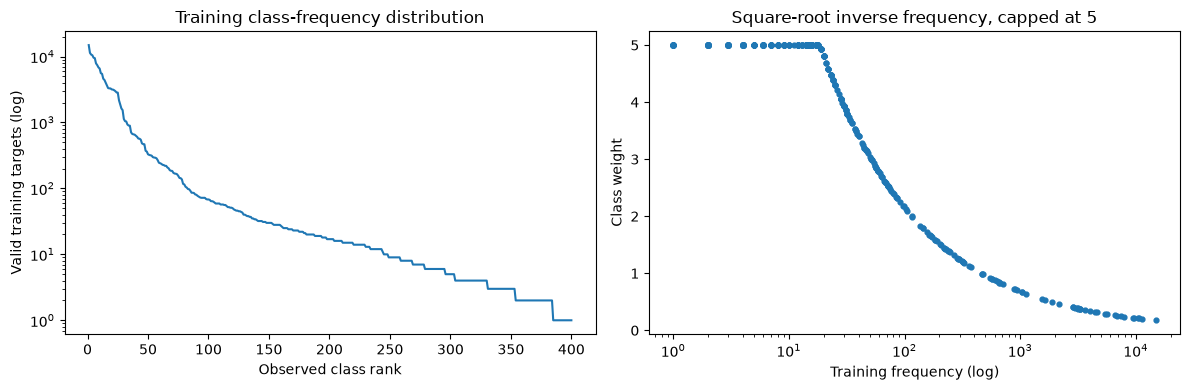

In [ ]:
training_counts=count_training_targets(frequency_loader,spec.num_target_classes,reserved_ids)
class_weights=sqrt_inverse_weights(training_counts,alpha=ALPHA,maximum=MAX_WEIGHT)
assert training_counts[list(reserved_ids)].sum()==0
assert len(class_weights)==spec.num_target_classes and torch.isfinite(class_weights).all()
observed_ids=torch.nonzero(training_counts>0).flatten().tolist()
assert int(training_counts.sum())>0
weight_rows=[{'target_id':i,'target_chord':label,'reserved':i in reserved_ids,
    'training_count':int(training_counts[i]),'class_weight':float(class_weights[i])}
    for i,label in enumerate(spec.target_labels)]
write_csv(RUN_DIR/'class_weights.csv',weight_rows)
atomic_json(RUN_DIR/'training_class_counts.json',{'source_split':'train','valid_targets':int(training_counts.sum()),
    'observed_classes':len(observed_ids),'zero_count_all_classes':int((training_counts==0).sum()),
    'zero_count_supervised_classes':sum(int(training_counts[i]==0) for i in range(len(training_counts)) if i not in reserved_ids),
    'alpha':ALPHA,'maximum_weight':MAX_WEIGHT,'counts':training_counts.tolist(),'weights':class_weights.tolist()})
ranked=sorted((weight_rows[i] for i in observed_ids),key=lambda row:(-row['training_count'],row['target_id']))
print('Valid training targets:',int(training_counts.sum()),'Observed supervised classes:',len(observed_ids))
print('Zero-training classes, including reserved:',int((training_counts==0).sum()))
print('Zero-training supervised classes:',sum(int(training_counts[i]==0) for i in range(len(training_counts)) if i not in reserved_ids))
print('20 most frequent:'); display(ranked[:20])
print('20 least frequent observed:'); display(sorted(ranked,key=lambda row:(row['training_count'],row['target_id']))[:20])
from html import escape
weight_table='<table><tr><th>ID</th><th>Target chord</th><th>Train count</th><th>Weight</th></tr>'+''.join(
    f"<tr><td>{row['target_id']}</td><td>{escape(row['target_chord'])}</td><td>{row['training_count']}</td><td>{row['class_weight']:.6f}</td></tr>" for row in weight_rows)+'</table>'
from IPython.display import HTML
display(HTML('<div style="max-height:450px;overflow:auto">'+weight_table+'</div>'))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(range(1,len(ranked)+1),[row['training_count'] for row in ranked]); axes[0].set_yscale('log')
axes[0].set(xlabel='Observed class rank',ylabel='Valid training targets (log)',title='Training class-frequency distribution')
axes[1].scatter([row['training_count'] for row in ranked],[row['class_weight'] for row in ranked],s=12)
axes[1].set_xscale('log'); axes[1].set(xlabel='Training frequency (log)',ylabel='Class weight',title='Square-root inverse frequency, capped at 5')
fig.tight_layout(); fig.savefig(RUN_DIR/'class_frequency.png',dpi=160); plt.show()

## 5. Unchanged model and a finite-gradient check

The model configuration is loaded directly from the baseline run. This check backpropagates without taking an optimizer step, in eval mode so it consumes no dropout RNG. Gradients are cleared before actual training. We compare the state to confirm the check did not update weights.

In [8]:
model_config=ModelConfig(**baseline_config['model'])
model=ChordRefinementTransformer(spec,model_config).to(DEVICE)
assert asdict(model_config)==baseline_config['model']
assert sum(p.numel() for p in model.parameters())==baseline_config['parameters']
example_batch=collate_sequences([train_data[i] for i in range(4)])
example_inputs,example_targets=select_batch(example_batch,DEVICE)
weight_tensor=class_weights.to(DEVICE)
model.eval()
check_before={name:p.detach().clone() for name,p in model.named_parameters()}
example_logits=model(example_inputs)
check_loss=weighted_masked_cross_entropy(example_logits,example_targets,example_inputs['beat_attention_mask'],weight_tensor,reserved_ids)
check_loss.backward()
assert torch.isfinite(check_loss)
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters())
assert all(torch.equal(check_before[name],p) for name,p in model.named_parameters())
model.zero_grad(set_to_none=True)
print('Same parameters:',sum(p.numel() for p in model.parameters()),'Weighted check loss:',float(check_loss.detach()))
print('Finite gradients; no parameter update during this check.')

Same parameters: 349074 Weighted check loss: 6.005218982696533
Finite gradients; no parameter update during this check.


## 6. Weighted training and unweighted validation

PyTorch weighted CE divides the weighted loss sum by the sum of selected target weights, not by the number of examples. Epoch weighted loss uses the same denominator across batches. We also track ordinary CE for train and validation on a common scale.

Training minimizes weighted CE. The scheduler and early stopping receive **ordinary unweighted validation CE**, matching the baseline. Weighted validation CE is diagnostic only. Empty or all-zero-weight supervision returns differentiable zero.

In [9]:
def run_weighted_epoch(model,loader,device,weights,optimizer=None,label='',log_every=100):
    training=optimizer is not None
    model.train(training)
    weighted_sum=weight_sum=ordinary_sum=0.0
    correct=count=beats=sequences=steps=0
    started=time.perf_counter()
    for number,batch in enumerate(loader,1):
        inputs,targets=select_batch(batch,device)
        mask=supervised_mask(targets,inputs['beat_attention_mask'],spec.num_target_classes,reserved_ids)
        ids=targets['target_chord_ids'][mask]
        active=int(ids.numel())
        if training: optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits=model(inputs)
            weighted_loss=weighted_masked_cross_entropy(logits,targets,inputs['beat_attention_mask'],weights,reserved_ids)
            if not torch.isfinite(logits).all() or not torch.isfinite(weighted_loss): raise FloatingPointError('Non-finite loss/logits')
            if training and active and weights[ids].sum()>0:
                weighted_loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(),baseline_config['clip_norm'],error_if_nonfinite=True)
                optimizer.step(); steps+=1
        with torch.no_grad():
            if active:
                ordinary=F.cross_entropy(logits[mask],ids,reduction='none')
                ordinary_sum+=float(ordinary.sum())
                weighted_sum+=float((ordinary*weights[ids]).sum())
                weight_sum+=float(weights[ids].sum())
                correct+=int((logits.argmax(-1)[mask]==ids).sum())
        count+=active; beats+=int(inputs['beat_attention_mask'].sum()); sequences+=len(inputs['beat_attention_mask'])
        if log_every and (number==1 or number%log_every==0):
            print(f'{label} batch {number}/{len(loader)} weighted CE={weighted_sum/max(weight_sum,1e-12):.5f} unweighted CE={ordinary_sum/max(count,1):.5f}',flush=True)
    if not count: raise ValueError('No supervised real targets')
    return {'loss':ordinary_sum/count,'weighted_loss':weighted_sum/weight_sum if weight_sum else 0.0,
            'weight_sum':weight_sum,'accuracy':correct/count,'correct_targets':correct,'valid_targets':count,
            'real_beats':beats,'sequences':sequences,'optimizer_steps':steps,'seconds':time.perf_counter()-started}

optimizer=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=baseline_config['weight_decay'])
scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,factor=0.5,patience=1)
experiment_config={**baseline_config,'run_dir':str(RUN_DIR),'baseline_run':str(BASELINE_RUN),
    'loss':'class-weighted cross entropy','weight_source':'train only','alpha':ALPHA,'maximum_weight':MAX_WEIGHT,
    'selection':'minimum ordinary unweighted validation cross entropy','protected_hashes':protected_hashes}
atomic_json(RUN_DIR/'experiment_config.json',experiment_config)
initial_validation=run_weighted_epoch(model,validation_loader,DEVICE,weight_tensor,label='Initial validation',log_every=0)
atomic_json(RUN_DIR/'initial_validation.json',initial_validation)
display(initial_validation)

{'loss': 6.053405598435828,
 'weighted_loss': 6.107626261871749,
 'weight_sum': 5107.414024353027,
 'accuracy': 0.01141430354913501,
 'correct_targets': 128,
 'valid_targets': 11214,
 'real_beats': 11319,
 'sequences': 814,
 'optimizer_steps': 0,
 'seconds': 1.3574954999930924}

## 7. Train the separate weighted experiment

In [10]:
if (RUN_DIR/'history.json').exists():
    raise RuntimeError('This run has training history. Run All to create a fresh run directory.')
history = []
best_loss, best_epoch, stale = float('inf'), 0, 0
training_started = time.perf_counter()
try:
    for epoch in range(1,MAX_EPOCHS+1):
        atomic_json(RUN_DIR/'status.json',{'status':'training','epoch':epoch,'max_epochs':MAX_EPOCHS})
        current_lr = optimizer.param_groups[0]['lr']
        train_metrics = run_weighted_epoch(model,train_loader,DEVICE,weight_tensor,optimizer,label=f'Epoch {epoch} train')
        validation_metrics = run_weighted_epoch(model,validation_loader,DEVICE,weight_tensor,label=f'Epoch {epoch} validation',log_every=0)
        assert train_metrics['sequences']==indices['train']['sequences']
        assert train_metrics['real_beats']==indices['train']['real_beats']
        assert validation_metrics['sequences']==indices['validation']['sequences']
        scheduler.step(validation_metrics['loss'])
        improved = validation_metrics['loss']<best_loss
        if improved:
            best_loss,best_epoch,stale = validation_metrics['loss'],epoch,0
            save_checkpoint(RUN_DIR/'best_weighted.pt.tmp',model)
            (RUN_DIR/'best_weighted.pt.tmp').replace(RUN_DIR/'best_weighted.pt')
        else:
            stale += 1
        history.append({'epoch':epoch,'learning_rate':current_lr,'train':train_metrics,
                        'validation':validation_metrics,'saved_best':improved})
        atomic_json(RUN_DIR/'history.json',history)
        write_csv(RUN_DIR/'training_history.csv',[{'epoch':r['epoch'],'learning_rate':r['learning_rate'],
            'train_weighted_ce':r['train']['weighted_loss'],'train_unweighted_ce':r['train']['loss'],
            'validation_unweighted_ce':r['validation']['loss'],'validation_weighted_ce_diagnostic':r['validation']['weighted_loss'],
            'train_accuracy':r['train']['accuracy'],'validation_accuracy':r['validation']['accuracy'],
            'saved_best':r['saved_best']} for r in history])
        torch.save({'epoch':epoch,'model_config':asdict(model_config),'spec':asdict(spec),
                    'class_weights':class_weights,'training_counts':training_counts,'model_state_dict':model.state_dict(),'optimizer_state_dict':optimizer.state_dict(),
                    'scheduler_state_dict':scheduler.state_dict(),'best_epoch':best_epoch,
                    'best_validation_loss':best_loss,'rng_state':torch.get_rng_state(),
                    'shuffle_rng_state':train_loader.generator.get_state()},RUN_DIR/'last_weighted_training_state.pt.tmp')
        (RUN_DIR/'last_weighted_training_state.pt.tmp').replace(RUN_DIR/'last_weighted_training_state.pt')
        print(f'Epoch {epoch}: train loss {train_metrics["loss"]:.5f}, '
              f'validation loss {validation_metrics["loss"]:.5f}, '
              f'validation accuracy {validation_metrics["accuracy"]:.2%}; best epoch {best_epoch}',flush=True)
        if stale>=PATIENCE:
            print('Early stopping: validation loss did not improve.',flush=True)
            break
    atomic_json(RUN_DIR/'status.json',{'status':'trained_pending_evaluation',
                                     'completed_epochs':len(history),'best_epoch':best_epoch})
except BaseException as exc:
    atomic_json(RUN_DIR/'status.json',{'status':'interrupted' if isinstance(exc,KeyboardInterrupt) else 'failed',
                                     'error':repr(exc),'completed_epochs':len(history)})
    raise
print('Training seconds:',round(time.perf_counter()-training_started,2))

Epoch 1 train batch 1/398 weighted CE=6.27774 unweighted CE=6.30764


Epoch 1 train batch 100/398 weighted CE=3.67618 unweighted CE=2.21229


Epoch 1 train batch 200/398 weighted CE=2.96135 unweighted CE=1.57473


Epoch 1 train batch 300/398 weighted CE=2.62488 unweighted CE=1.31883


Epoch 1: train loss 1.17758, validation loss 0.76478, validation accuracy 81.78%; best epoch 1


...

Epoch 5 train batch 200/398 weighted CE=0.69912 unweighted CE=0.39925


Epoch 5 train batch 300/398 weighted CE=0.68308 unweighted CE=0.39801


Epoch 5: train loss 0.39224, validation loss 0.76012, validation accuracy 77.27%; best epoch 2


Early stopping: validation loss did not improve.


Training seconds: 338.01


## 8. Learning curves

The left plot uses unweighted CE for both splits so it is comparable. The middle plot shows weighted CE separately; scales should not be directly compared across objectives. Validation accuracy is descriptive, not the checkpoint selection rule.

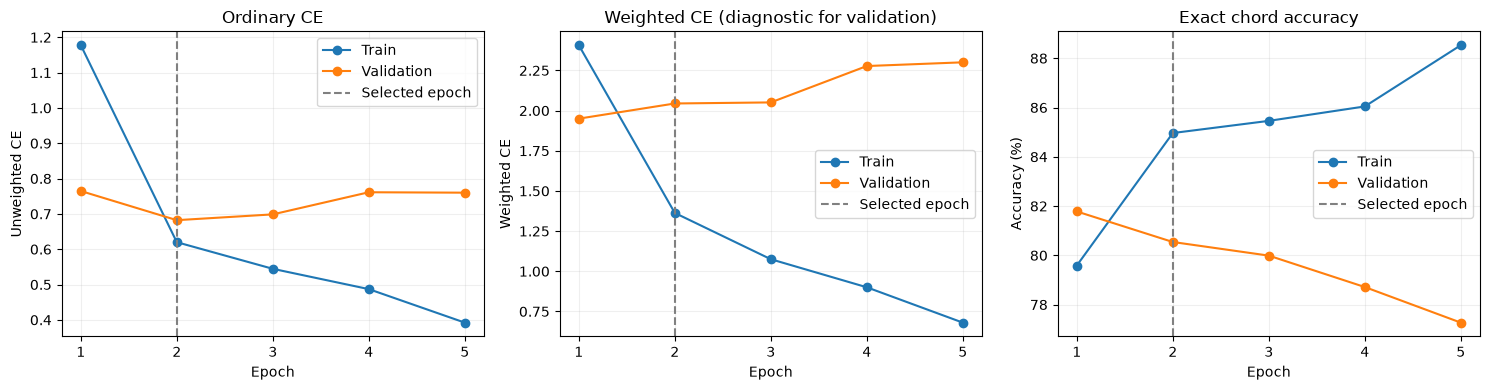

In [11]:
epochs=[r['epoch'] for r in history]
fig,axes=plt.subplots(1,3,figsize=(15,4))
for key,name in [('train','Train'),('validation','Validation')]:
    axes[0].plot(epochs,[r[key]['loss'] for r in history],marker='o',label=name)
    axes[1].plot(epochs,[r[key]['weighted_loss'] for r in history],marker='o',label=name)
    axes[2].plot(epochs,[100*r[key]['accuracy'] for r in history],marker='o',label=name)
for ax,title,ylabel in zip(axes,['Ordinary CE','Weighted CE (diagnostic for validation)','Exact chord accuracy'],['Unweighted CE','Weighted CE','Accuracy (%)']):
    ax.set(xlabel='Epoch',ylabel=ylabel,title=title); ax.set_xticks(epochs)
    ax.axvline(best_epoch,ls='--',color='gray',label='Selected epoch'); ax.legend(); ax.grid(alpha=0.2)
fig.tight_layout(); fig.savefig(RUN_DIR/'training_validation_curves.png',dpi=160); plt.show()

## 9. Identical held-out evaluation for both checkpoints

The baseline is loaded, not retrained. Metrics use the same test loader, input fields and saved target labels. Both masks exclude padding/unsupervised beats. Raw logits over all saved output classes determine top-1 and top-3, with reserved predictions retained as errors.

Macro F1 averages classes with **positive valid test-reference support**, excluding PAD/UNK and including supervised N. Zero-support classes remain visible in detailed reports but do not enter the macro mean. Weighted F1 weights those class F1 scores by test support. Undefined precision/recall is displayed N/A; supported classes with no true positives receive F1 zero.

In [12]:
def evaluate_checkpoint(model,loader):
    model.eval()
    confusion=torch.zeros(spec.num_target_classes,spec.num_target_classes,dtype=torch.int64)
    count=top3_correct=0; ce_sum=0.0
    with torch.no_grad():
        for batch in loader:
            inputs,targets=select_batch(batch,DEVICE)
            mask=supervised_mask(targets,inputs['beat_attention_mask'],spec.num_target_classes,reserved_ids)
            ids=targets['target_chord_ids'][mask]
            logits=model(inputs)[mask]
            if not torch.isfinite(logits).all(): raise FloatingPointError('Non-finite inference')
            predicted=logits.argmax(-1)
            count+=len(ids)
            top3_correct+=int((logits.topk(3,-1).indices==ids.unsqueeze(-1)).any(-1).sum())
            ce_sum+=float(F.cross_entropy(logits,ids,reduction='sum')) if len(ids) else 0.0
            flat=(ids*spec.num_target_classes+predicted).cpu()
            confusion+=torch.bincount(flat,minlength=spec.num_target_classes**2).reshape(spec.num_target_classes,spec.num_target_classes)
    summary,per_class=metrics_from_confusion(confusion,spec.target_labels,reserved_ids)
    assert summary['valid_targets']==count
    summary.update(unweighted_ce=ce_sum/count,top3_accuracy=top3_correct/count,top3_correct=top3_correct)
    return summary,per_class,quality_metrics(confusion,spec.target_labels),confusion

weighted_model=load_checkpoint(RUN_DIR/'best_weighted.pt',DATASET_DIR,DEVICE)
baseline_model=load_checkpoint(BASELINE_RUN/'best.pt',DATASET_DIR,DEVICE)
assert asdict(weighted_model.config)==asdict(baseline_model.config)==baseline_config['model']
assert weighted_model.spec==baseline_model.spec
test_data=CachedSelectedDataset(DATASET_DIR/'test_sequences.json')
test_loader=make_dataloader(test_data,batch_size=BATCH_SIZE,shuffle=False,seed=SEED)
baseline_metrics,baseline_classes,baseline_qualities,baseline_confusion=evaluate_checkpoint(baseline_model,test_loader)
weighted_metrics,weighted_classes,weighted_qualities,weighted_confusion=evaluate_checkpoint(weighted_model,test_loader)
write_csv(RUN_DIR/'baseline_per_class.csv',baseline_classes)
write_csv(RUN_DIR/'weighted_per_class.csv',weighted_classes)
write_csv(RUN_DIR/'baseline_per_chord_quality.csv',baseline_qualities)
write_csv(RUN_DIR/'weighted_per_chord_quality.csv',weighted_qualities)
atomic_json(RUN_DIR/'evaluation_metrics.json',{'baseline':baseline_metrics,'weighted':weighted_metrics,
    'completed_epochs':len(history),'best_epoch':best_epoch})
print('Macro policy:',baseline_metrics['macro_policy'])
display({'baseline':baseline_metrics,'weighted':weighted_metrics})

Macro policy: Positive test-reference support, excluding reserved PAD/UNK; supervised N included.


{'baseline': {'valid_targets': 14077,
  'exact_correct': 11192,
  'accuracy': 0.7950557647225971,
  'macro_f1': 0.32597766423563834,
  'weighted_f1': 0.7349953243341616,
  'macro_classes': 104,
  'macro_policy': 'Positive test-reference support, excluding reserved PAD/UNK; supervised N included.',
  'unweighted_ce': 0.8552253938850933,
  'top3_accuracy': 0.9417489521915181,
  'top3_correct': 13257},
 'weighted': {'valid_targets': 14077,
  'exact_correct': 11050,
  'accuracy': 0.7849683881508844,
  'macro_f1': 0.3198755370699484,
  'weighted_f1': 0.7366717045868174,
  'macro_classes': 104,
  'macro_policy': 'Positive test-reference support, excluding reserved PAD/UNK; supervised N included.',
  'unweighted_ce': 0.9244743233895009,
  'top3_accuracy': 0.9246288271648789,
  'top3_correct': 13016}}

## 10. Baseline versus weighted comparison and individual qualities

Quality rows are individual labels such as maj7 and min7; extensions are not collapsed. A correct prediction must match root, detailed quality and inversion. Supported parser qualities without test examples show N/A. No-chord remains a legitimate supervised target in overall metrics.

In [13]:
quality_baseline={r['reference_quality']:r for r in baseline_qualities}
quality_weighted={r['reference_quality']:r for r in weighted_qualities}
comparison=[]
for name,key in [('Test accuracy','accuracy'),('Macro F1 (positive test support)','macro_f1'),('Weighted F1','weighted_f1'),('Top-3 accuracy','top3_accuracy')]:
    comparison.append({'metric':name,'baseline':baseline_metrics[key],'weighted':weighted_metrics[key],
                       'change_percentage_points':100*(weighted_metrics[key]-baseline_metrics[key]),'support':baseline_metrics['valid_targets']})
for name,quality in [('Major accuracy','maj'),('Minor accuracy','min'),('Minor seventh accuracy','min7'),
                     ('Major seventh accuracy','maj7'),('Dominant seventh accuracy','7'),('Diminished accuracy','dim'),('Augmented accuracy','aug')]:
    b,w=quality_baseline[quality],quality_weighted[quality]
    comparison.append({'metric':name,'baseline':b['exact_chord_accuracy'],'weighted':w['exact_chord_accuracy'],
        'change_percentage_points':100*(w['exact_chord_accuracy']-b['exact_chord_accuracy']) if b['support'] else None,'support':b['support']})
write_csv(RUN_DIR/'baseline_vs_weighted_comparison.csv',comparison)
quality_comparison=[{'quality':q,'support':quality_baseline[q]['support'],
    'baseline_exact_accuracy':quality_baseline[q]['exact_chord_accuracy'],
    'weighted_exact_accuracy':quality_weighted[q]['exact_chord_accuracy']} for q in quality_baseline]
write_csv(RUN_DIR/'quality_comparison.csv',quality_comparison)
def render_table(rows,percentage_keys=()):
    headers=list(rows[0]); body=[]
    for row in rows:
        values=[('N/A' if row[k] is None else (f'{100*row[k]:.2f}%' if k in percentage_keys else str(row[k]))) for k in headers]
        body.append('<tr>'+''.join('<td style="padding:5px 10px">'+escape(v)+'</td>' for v in values)+'</tr>')
    return '<div style="max-height:550px;overflow:auto"><table><tr>'+''.join('<th style="padding:7px">'+escape(k)+'</th>' for k in headers)+'</tr>'+''.join(body)+'</table></div>'
display(HTML(render_table(comparison,('baseline','weighted'))))
display(HTML(render_table(quality_comparison,('baseline_exact_accuracy','weighted_exact_accuracy'))))
print('Weighted per-class table: zero-support rows are retained; macro eligibility is explicit.')
display(HTML(render_table(weighted_classes,('precision','recall','f1'))))

metric,baseline,weighted,change_percentage_points,support
Test accuracy,79.51%,78.50%,-1.0087376571712658,14077
Macro F1 (positive test support),32.60%,31.99%,-0.6102127165689919,14077
Weighted F1,73.50%,73.67%,0.1676380252655818,14077
Top-3 accuracy,94.17%,92.46%,-1.7120125026639177,14077
Major accuracy,96.92%,94.82%,-2.103174603174607,5040
Minor accuracy,90.46%,88.30%,-2.1518230723251652,5019
Minor seventh accuracy,20.98%,25.73%,4.756097560975611,1640
Major seventh accuracy,0.00%,0.00%,0.0,926
Dominant seventh accuracy,95.69%,91.69%,-3.9999999999999925,325
Diminished accuracy,0.00%,100.00%,100.0,7


quality,support,baseline_exact_accuracy,weighted_exact_accuracy
11,0,N/A,N/A
13,0,N/A,N/A
6,0,N/A,N/A
7,325,95.69%,91.69%
9,0,N/A,N/A
N,1112,100.00%,100.00%
add9,0,N/A,N/A
aug,8,0.00%,0.00%
dim,7,0.00%,100.00%
dim7,0,N/A,N/A


Weighted per-class table: zero-support rows are retained; macro eligibility is explicit.


target_id,reference_chord,quality,reserved,support,predicted_count,correct,precision,recall,f1,included_in_macro
0,PAD,PAD,True,0,0,0,N/A,N/A,N/A,False
1,UNK,UNK,True,0,0,0,N/A,N/A,N/A,False
2,N,N,False,1112,1112,1112,100.00%,100.00%,100.00%,True
3,A#:7,7,False,20,20,20,100.00%,100.00%,100.00%,True
4,A#:7/2,7,False,0,0,0,N/A,N/A,N/A,False
5,A#:7/3,7,False,0,0,0,N/A,N/A,N/A,False
6,A#:7/5,7,False,0,0,0,N/A,N/A,N/A,False
7,A#:7/6,7,False,0,0,0,N/A,N/A,N/A,False
8,A#:7/b2,7,False,0,0,0,N/A,N/A,N/A,False
9,A#:aug,aug,False,0,0,0,N/A,N/A,N/A,False


## 11. Confusion matrices and rare-class comparisons

The displayed confusion matrices use the same 15 most frequent test-reference classes for both models. Submatrix rows can omit predictions outside these 15 classes; the full confusion matrices are saved separately. Rare-class F1 plots select up to 20 classes with the smallest **training frequencies** among classes with positive test support, avoiding selection by observed improvement.

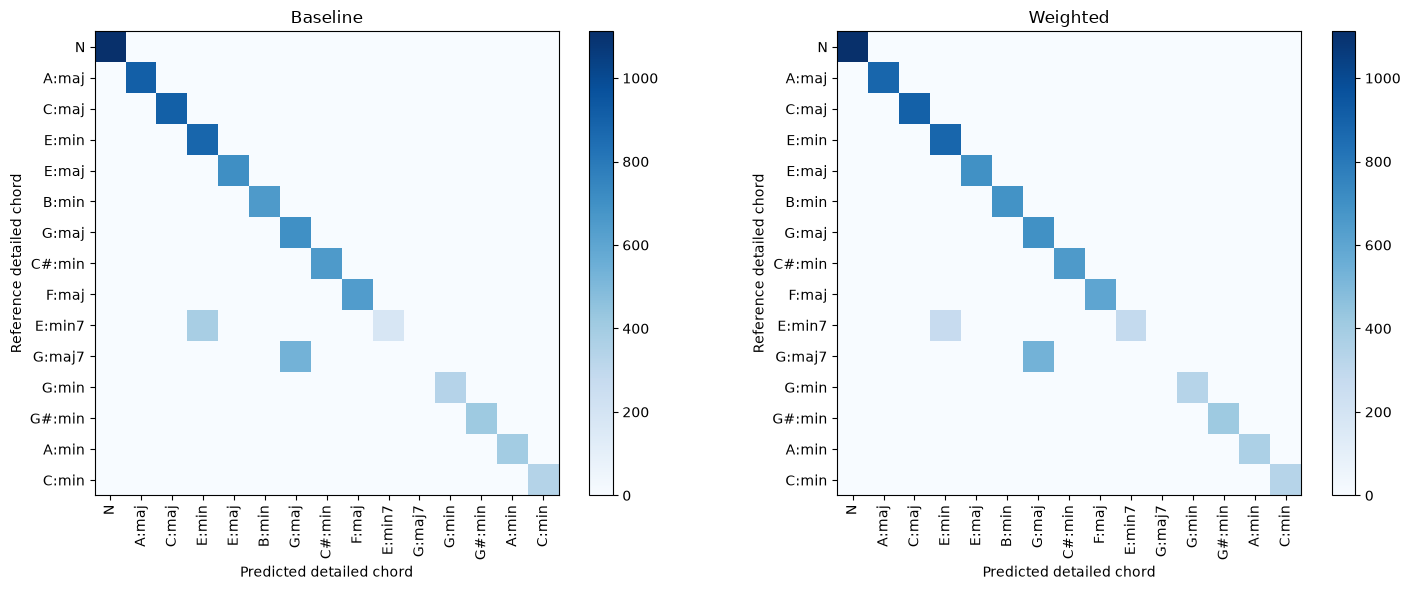

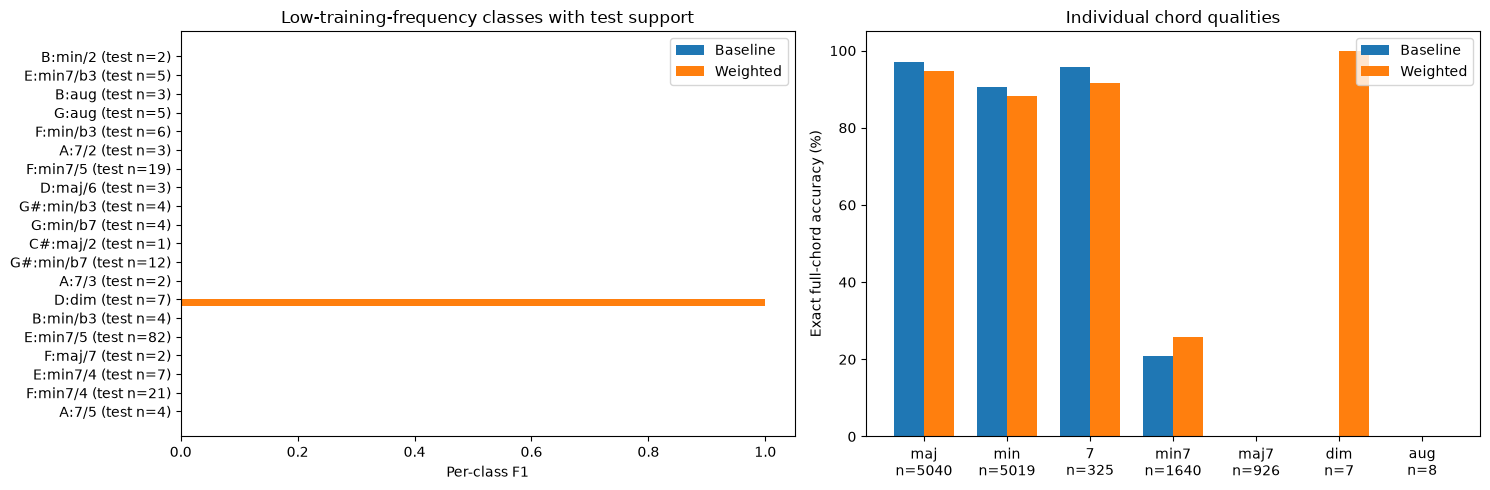

[{'chord': 'B:min/2',
  'train_support': 2,
  'test_support': 2,
  'baseline_f1': 0.0,
  'weighted_f1': 0.0,
  'f1_change': 0.0},
 {'chord': 'E:min7/b3',
  'train_support': 2,
  'test_support': 5,
  'baseline_f1': 0.0,
  'weighted_f1': 0.0,
  'f1_change': 0.0},
 {'chord': 'B:aug',
  'train_support': 3,
  'test_support': 3,
  'baseline_f1': 0.0,
  'weighted_f1': 0.0,
  'f1_change': 0.0},
 {'chord': 'G:aug',
  'train_support': 4,
  'test_support': 5,
  'baseline_f1': 0.0,
  'weighted_f1': 0.0,
  'f1_change': 0.0},
 {'chord': 'F:min/b3',
  'train_support': 5,
  'test_support': 6,
  'baseline_f1': 0.0,
  'weighted_f1': 0.0,
  'f1_change': 0.0},
 {'chord': 'A:7/2',
  'train_support': 6,
  'test_support': 3,
  'baseline_f1': 0.0,
  'weighted_f1': 0.0,
  'f1_change': 0.0},
 {'chord': 'F:min7/5',
  'train_support': 6,
  'test_support': 19,
  'baseline_f1': 0.0,
  'weighted_f1': 0.0,
  'f1_change': 0.0},
 {'chord': 'D:maj/6',
  'train_support': 8,
  'test_support': 3,
  'baseline_f1': 0.0,
  'w

In [14]:
test_support=baseline_confusion.sum(1)
frequent=test_support.argsort(descending=True,stable=True)[:15].tolist()
fig,axes=plt.subplots(1,2,figsize=(15,6))
maximum=max(int(baseline_confusion.max()),int(weighted_confusion.max()))
for ax,matrix,title in zip(axes,[baseline_confusion,weighted_confusion],['Baseline','Weighted']):
    sub=matrix[frequent][:,frequent].numpy()
    image=ax.imshow(sub,cmap='Blues',vmin=0,vmax=maximum)
    ax.set_xticks(range(len(frequent)),[spec.target_labels[i] for i in frequent],rotation=90)
    ax.set_yticks(range(len(frequent)),[spec.target_labels[i] for i in frequent])
    ax.set(title=title,xlabel='Predicted detailed chord',ylabel='Reference detailed chord')
    fig.colorbar(image,ax=ax,fraction=0.046)
fig.tight_layout(); fig.savefig(RUN_DIR/'frequent_class_confusion.png',dpi=170); plt.show()
np.savez_compressed(RUN_DIR/'confusion_matrices.npz',baseline=baseline_confusion.numpy(),weighted=weighted_confusion.numpy(),labels=np.asarray(spec.target_labels))
rare=sorted((i for i in observed_ids if test_support[i]>0),key=lambda i:(int(training_counts[i]),i))[:20]
rare_rows=[{'chord':spec.target_labels[i],'train_support':int(training_counts[i]),'test_support':int(test_support[i]),
    'baseline_f1':baseline_classes[i]['f1'],'weighted_f1':weighted_classes[i]['f1'],
    'f1_change':weighted_classes[i]['f1']-baseline_classes[i]['f1']} for i in rare]
write_csv(RUN_DIR/'rare_class_comparison.csv',rare_rows)
fig,axes=plt.subplots(1,2,figsize=(15,5))
y=np.arange(len(rare))
axes[0].barh(y-0.18,[baseline_classes[i]['f1'] for i in rare],height=0.36,label='Baseline')
axes[0].barh(y+0.18,[weighted_classes[i]['f1'] for i in rare],height=0.36,label='Weighted')
axes[0].set_yticks(y,[f'{spec.target_labels[i]} (test n={int(test_support[i])})' for i in rare]); axes[0].invert_yaxis()
axes[0].set(xlabel='Per-class F1',title='Low-training-frequency classes with test support'); axes[0].legend()
focus=[q for q in ('maj','min','7','min7','maj7','dim','aug') if quality_baseline[q]['support']]
x=np.arange(len(focus))
axes[1].bar(x-0.18,[100*quality_baseline[q]['exact_chord_accuracy'] for q in focus],width=0.36,label='Baseline')
axes[1].bar(x+0.18,[100*quality_weighted[q]['exact_chord_accuracy'] for q in focus],width=0.36,label='Weighted')
axes[1].set_xticks(x,[f'{q}\nn={quality_baseline[q]["support"]}' for q in focus])
axes[1].set(ylabel='Exact full-chord accuracy (%)',title='Individual chord qualities'); axes[1].legend()
fig.tight_layout(); fig.savefig(RUN_DIR/'rare_and_quality_comparison.png',dpi=170); plt.show()
display(rare_rows)

## 12. Integrity checks and measured conclusions

Original notebooks, architecture source, vocabularies and baseline checkpoint must remain byte-identical. All v6 readiness-manifest artifact hashes are checked. Reloaded weighted checkpoint outputs must match exactly. The final conclusion is computed from this run's measured results, not copied from prior reports.

In [15]:
for path,expected in protected_hashes.items(): assert sha256_file(path)==expected,path
ready=json.loads((DATASET_DIR/'FINAL_DATASET_READY.json').read_text())
for name,expected in ready['artifacts'].items(): assert sha256_file(DATASET_DIR/name)==expected,name
reloaded=load_checkpoint(RUN_DIR/'best_weighted.pt',DATASET_DIR,DEVICE)
with torch.no_grad():
    a=weighted_model(example_inputs); b=reloaded(example_inputs)
torch.testing.assert_close(a,b,rtol=0,atol=0)
assert all(torch.isfinite(p).all() for p in weighted_model.parameters())
assert len(weight_rows)==spec.num_target_classes
assert asdict(weighted_model.config)==baseline_config['model']
rare_improved=sum(r['f1_change']>0 for r in rare_rows)
rare_declined=sum(r['f1_change']<0 for r in rare_rows)
summary={'status':'complete','baseline':baseline_metrics,'weighted':weighted_metrics,
    'completed_epochs':len(history),'best_epoch':best_epoch,'alpha':ALPHA,'maximum_weight':MAX_WEIGHT,
    'observed_training_classes':len(observed_ids),'valid_training_targets':int(training_counts.sum()),
    'rare_subset_policy':'20 lowest-training-frequency observed classes with positive test support',
    'rare_subset_improved':rare_improved,'rare_subset_declined':rare_declined,
    'accuracy_change_percentage_points':100*(weighted_metrics['accuracy']-baseline_metrics['accuracy']),
    'macro_f1_change':weighted_metrics['macro_f1']-baseline_metrics['macro_f1'],
    'baseline_checkpoint_unchanged':True,'original_notebooks_unchanged':True,
    'dataset_artifacts_verified':len(ready['artifacts']),'checkpoint_reload_matches':True,
    'input_and_model_config_match_baseline':True,'weights_fit_on_training_only':True,
    'limitations':'Single seed, synthetic reference-derived inputs, automatic pseudo-labels. No independent musical accuracy claim.'}
atomic_json(RUN_DIR/'results.json',summary)
atomic_json(RUN_DIR/'status.json',{'status':'complete','best_epoch':best_epoch,'completed_epochs':len(history)})
print('Exact accuracy change (percentage points):',summary['accuracy_change_percentage_points'])
print('Macro F1 change:',summary['macro_f1_change'])
print('Low-frequency displayed subset improved/declined:',rare_improved,rare_declined,'of',len(rare_rows))
print('Output directory:',RUN_DIR)
display(summary)

Exact accuracy change (percentage points): -1.0087376571712658
Macro F1 change: -0.006102127165689919
Low-frequency displayed subset improved/declined: 1 0 of 20
Output directory: C:\Users\srjay\OneDrive\Desktop\Research\vocal-harmonization\experiments\rahul\outputs\weighted_transformer\weighted_20261020_003318_832489


{'status': 'complete',
 'baseline': {'valid_targets': 14077,
  'exact_correct': 11192,
  'accuracy': 0.7950557647225971,
  'macro_f1': 0.32597766423563834,
  'weighted_f1': 0.7349953243341616,
  'macro_classes': 104,
  'macro_policy': 'Positive test-reference support, excluding reserved PAD/UNK; supervised N included.',
  'unweighted_ce': 0.8552253938850933,
  'top3_accuracy': 0.9417489521915181,
  'top3_correct': 13257},
 'weighted': {'valid_targets': 14077,
  'exact_correct': 11050,
  'accuracy': 0.7849683881508844,
  'macro_f1': 0.3198755370699484,
  'weighted_f1': 0.7366717045868174,
  'macro_classes': 104,
  'macro_policy': 'Positive test-reference support, excluding reserved PAD/UNK; supervised N included.',
  'unweighted_ce': 0.9244743233895009,
  'top3_accuracy': 0.9246288271648789,
  'top3_correct': 13016},
 'completed_epochs': 5,
 'best_epoch': 2,
 'alpha': 0.5,
 'maximum_weight': 5.0,
 'observed_training_classes': 400,
 'valid_training_targets': 184867,
 'rare_subset_policy'

## Reuse and interpretation

Load `best_weighted.pt` using the existing `load_checkpoint(path, DATASET_DIR)` utility. A new Run All initializes a fresh model and writes a new run; no baseline file is overwritten. Training frequency and class-weight tables cover every saved target ID. Per-class CSVs retain zero-support labels, with empty cells for undefined metrics and explicit macro eligibility. CSV values are numeric fractions, not percentage strings.

Class weighting can improve rare labels while lowering exact accuracy on common labels. Judge it using the computed quality table, macro F1, weighted F1 and top-3 accuracy together, with support counts. Low-support results are unstable. One controlled seeded run does not establish statistical significance or independent musical correctness.